In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("loandataset.csv")

print("Dataset loaded successfully!")

print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

Dataset loaded successfully!
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural      

In [6]:
print("Missing Values:")

print(df.isnull().sum())

print("\nDuplicate Records:")

print(df.duplicated().sum())

df = df.drop("Loan_ID", axis=1)

# Convert target into numerical values
df["Loan_Status"] = df["Loan_Status"].map({
    "Y": 1,
    "N": 0
})

print(df.head())

print("\nTarget Values:")
print(df["Loan_Status"].value_counts())


Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate Records:
0
  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         NaN             360.0             1.0   
1             1508.0       128.0        

In [7]:
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

print("Input Features:")
print(X.head())

print("\nOutput:")
print(y.head())

Input Features:
  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         NaN             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area  
0         Urban  
1         Rural  
2         Urban  
3         Urban  
4         Urban 

In [8]:
numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History"
]

categorical_features = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area"
]

print("Numerical Features:", numeric_features)

print("Categorical Features:", categorical_features)

Numerical Features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical Features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [9]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Data preprocessing completed!")

Data preprocessing completed!


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (491, 11)
Testing Data: (123, 11)


In [11]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [12]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 1 1 1 1 0 1 1 1 1]

Predicted Values:
[0 1 1 1 1 1 1 1 1 1]


In [13]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("LOAN APPROVAL MODEL EVALUATION")

print("--------------------------------")

print("Accuracy :", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))

print("Recall   :", round(recall, 4))

print("F1 Score :", round(f1, 4))

print("ROC-AUC  :", round(roc_auc, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"]
))

LOAN APPROVAL MODEL EVALUATION
--------------------------------
Accuracy : 86.18 %
Precision: 0.84
Recall   : 0.9882
F1 Score : 0.9081
ROC-AUC  : 0.8523

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



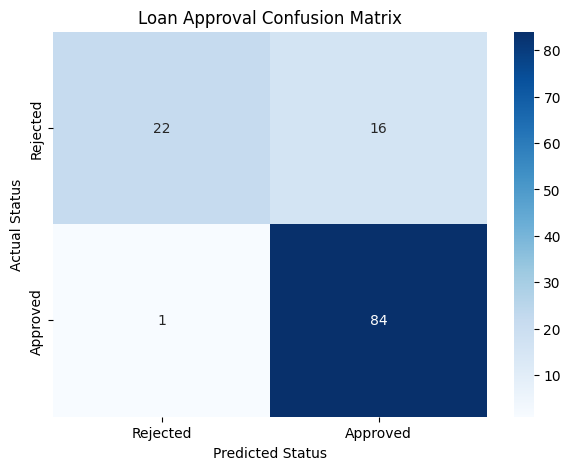

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.xlabel("Predicted Status")

plt.ylabel("Actual Status")

plt.title("Loan Approval Confusion Matrix")

plt.savefig("confusion_matrix.png")

plt.show()

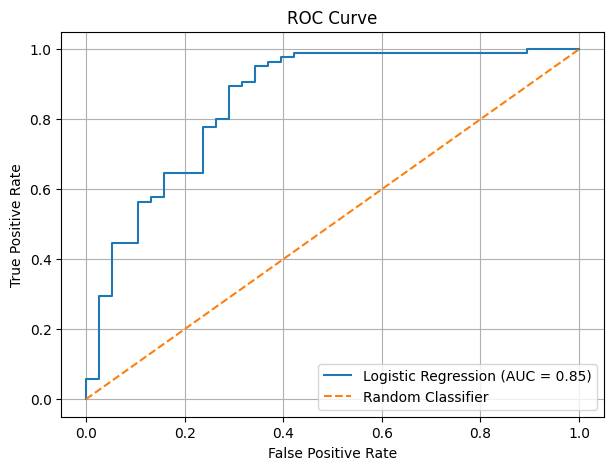

In [15]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid()

plt.savefig("roc_curve.png")

plt.show()

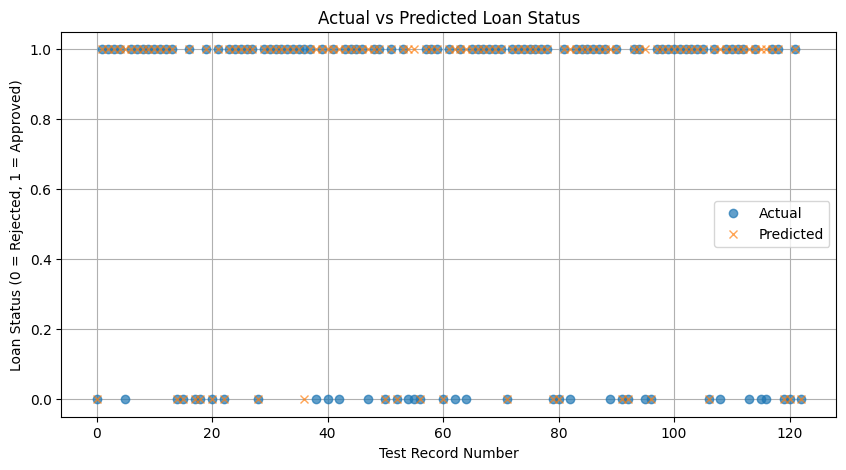

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    "o",
    label="Actual",
    alpha=0.7
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    "x",
    label="Predicted",
    alpha=0.7
)

plt.xlabel("Test Record Number")

plt.ylabel("Loan Status (0 = Rejected, 1 = Approved)")

plt.title("Actual vs Predicted Loan Status")

plt.legend()

plt.grid()

plt.savefig("actual_vs_predicted.png")

plt.show()

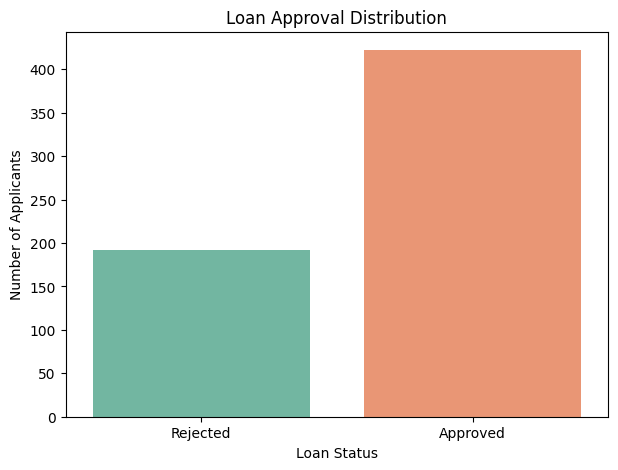

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status",
    hue="Loan_Status",
    palette="Set2",
    legend=False
)

plt.xticks(
    [0, 1],
    ["Rejected", "Approved"]
)

plt.xlabel("Loan Status")

plt.ylabel("Number of Applicants")

plt.title("Loan Approval Distribution")

plt.savefig("loan_distribution.png")

plt.show()

In [18]:
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "0",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 6000,
    "CoapplicantIncome": 2000,
    "LoanAmount": 120,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}])

# Prediction
prediction = model.predict(new_applicant)[0]

# Approval probability
probability = model.predict_proba(new_applicant)[0][1] * 100

print("NEW APPLICANT LOAN PREDICTION")

print("--------------------------------")

if prediction == 1:
    print("Loan Status: APPROVED")
else:
    print("Loan Status: REJECTED")

print("Approval Probability:", round(probability, 2), "%")

NEW APPLICANT LOAN PREDICTION
--------------------------------
Loan Status: APPROVED
Approval Probability: 79.9 %
